# Chapter 3: Polynomial Regression excercise

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

## 3.1 Introduction & Motivation

While linear regression in itself is an interesting tool, it can only bring us so far. At a certain point data will no longer have a linear connection and we will have to resort to using **polynomial regression**. Using an example regarding cars we will compare both forms of regression and try to end up with the best model possible.

## 3.2 Problem setting

Every car has a certain distance it can drive per unit of fuel. In the industry, this is measured in **MPG** (or Miles Per Gallon). The higher the MPG, the more fuel-efficient a certain car is. Generally speaking we want a high MPG to save money on fuel cost.

## 3.3 Model

Go to canvas and donload the file "Auto.csv" from module 3. This data contains the required dataset.

In [80]:
df = pd.read_csv("Auto.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [6]:
df["origin"]

0      1
1      1
2      1
3      1
4      1
      ..
393    1
394    2
395    1
396    1
397    1
Name: origin, Length: 398, dtype: int64

##### Question 1: Have a look at the data. Can you spot a column we will not be able to use? Why is this? Can you think of a way to transform this type of data so we could use it after all? Would work for the data we currently have? Elaborate.

##### Question 2: Drop the extra column. Create a train_test split from the remaining data. Make sure **not** to include the final mpg colum in your "X" dataset!

In [97]:
df = df.drop("car name", axis=1)

KeyError: "['car name'] not found in axis"

In [98]:
df = pd.get_dummies(df, columns=["origin"])
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin_1,origin_2,origin_3
0,18.0,8,307.0,130,3504,12.0,70,True,False,False
1,15.0,8,350.0,165,3693,11.5,70,True,False,False
2,18.0,8,318.0,150,3436,11.0,70,True,False,False
3,16.0,8,304.0,150,3433,12.0,70,True,False,False
4,17.0,8,302.0,140,3449,10.5,70,True,False,False
...,...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,True,False,False
394,44.0,4,97.0,52,2130,24.6,82,False,True,False
395,32.0,4,135.0,84,2295,11.6,82,True,False,False
396,28.0,4,120.0,79,2625,18.6,82,True,False,False


Since we are working with a lot of variables, it is time to plot a heatmap.

<Axes: >

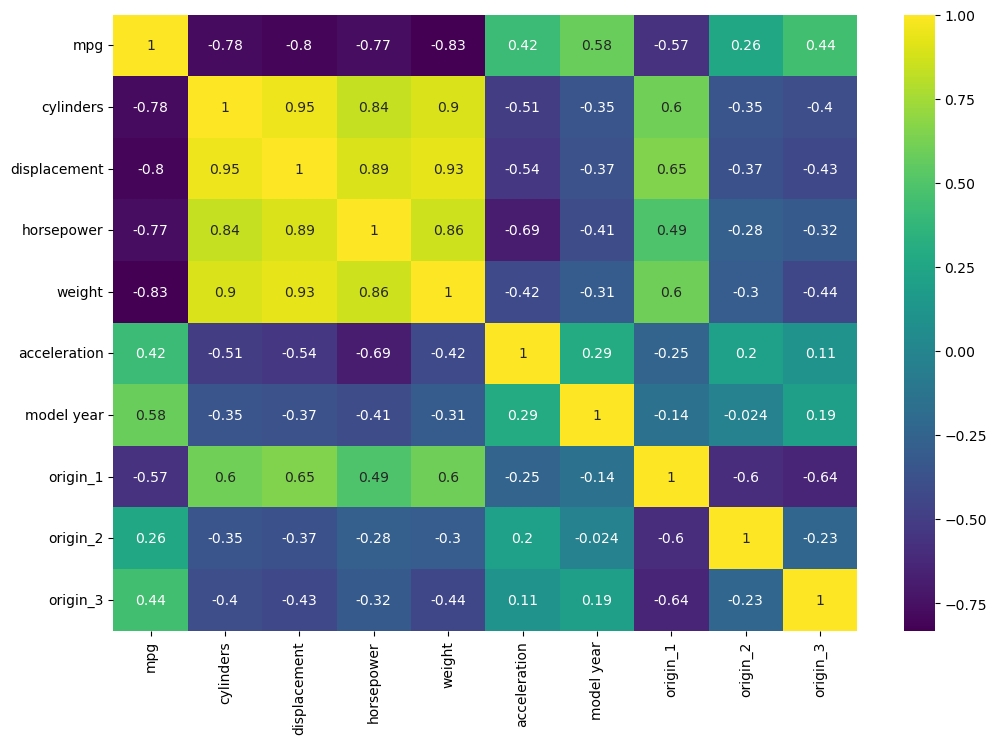

In [11]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),cmap='viridis',annot=True)

##### Question 3: Explore the heatmap. Which variables would you expect to be useful when trying to predict MPG?

##### Question 4: Plot the data using "weight" as the independant variable and 'MPG' as the dependant variable. Fit a model using linear regression. Calculate $R^2$ and the MSE. Is this any good? Show the model on a plot and elaborate.

##### Question 5: Create a model using polynomial regression. Make an educated guess on the degree of the function and plot the model. Calculate the $R^2$ and MSE. Compare this to the metrics of your linear regression model. Is there an improvement?

In [ ]:
# Question 3
# => The more cilinders, the more fuel is being consumed = less MPG. Strong negative correlation between #cilinders & MGP

# => The higher the weight, the lesser the MPG (it takes a lot more fuel to move something heavy than something light)

# => The more cilinders, the higher the discplacement (cc)

# => 

In [19]:
df = df.sort_values("weight")

In [58]:
X = df["weight"].to_numpy().reshape(-1, 1)
y = df["mpg"]

train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.25, random_state=42)

model = LinearRegression()

model.fit(train_X, train_y)

print("R2:",model.score(train_X, train_y))

y_pred = model.predict(test_X)
print("MSE:", mean_squared_error(y_pred, test_y))

R2: 0.663939361254891
MSE: 20.93344177627695


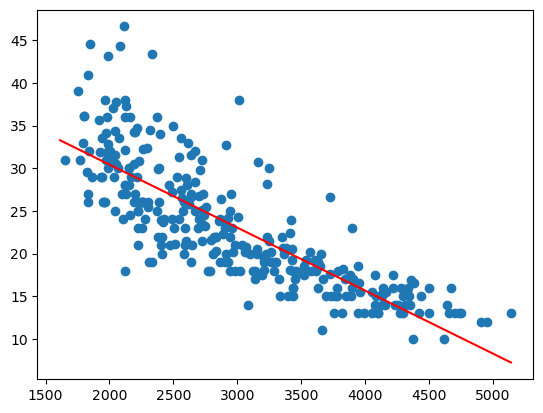

In [59]:
x_max = X.max() * model.coef_[0] + model.intercept_
x_min = X.min() * model.coef_[0] + model.intercept_

plt.scatter(train_X, train_y)
plt.plot([X.min(), X.max()], [x_min, x_max], color="red")

In [60]:
polymodel = LinearRegression()

pol_0 = PolynomialFeatures(degree=3)
polymodel.fit(pol_0.fit_transform(train_X), train_y)

LinearRegression()

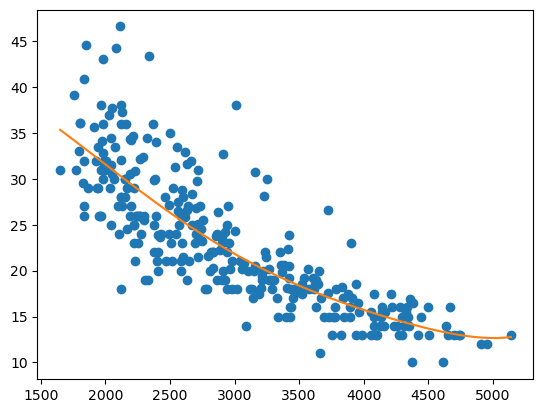

In [61]:
polymodel = LinearRegression()

pol_0 = PolynomialFeatures(degree=6)
polymodel.fit(pol_0.fit_transform(train_X), train_y)

Magix = np.linspace(train_X.min(), train_X.max(), 100).reshape(-1,1) 
plt.plot(train_X, train_y, 'o')
plt.plot(Magix, polymodel.predict(pol_0.fit_transform(Magix))) 
plt.show()

In [62]:
y_pred = polymodel.predict(pol_0.fit_transform(test_X))

print("R2:", polymodel.score(pol_0.fit_transform(test_X), test_y))
print('The MSE score:', mean_squared_error(y_pred, test_y))

R2: 0.7633593732886415
The MSE score: 18.907552707909176


## 3.4 Model evaluation

We already did some early model evaluating, but we can look for a better degree of our function to improve the model.

##### Question 6: Figure out what the best degree of the function is. Calculate the MSE for each degree on training and testing data and plot the values to figure out the best value. be careful of overfitting!

In [74]:
train_MSE = []
test_MSE = []
    

for i in range(0, 50):
    print("DEGREE:", i)
    pol_0 = PolynomialFeatures(degree=i)
    polymodel.fit(pol_0.fit_transform(train_X), train_y)

    Magix = np.linspace(train_X.min(), train_X.max(), 100).reshape(-1,1) 
    y_pred = polymodel.predict(pol_0.fit_transform(test_X))
    y_pred_train = polymodel.predict(pol_0.fit_transform(train_X))

    #(polymodel.score(pol_0.fit_transform(test_X), test_y))
    test_MSE.append(mean_squared_error(y_pred, test_y))
    train_MSE.append(mean_squared_error(y_pred_train, train_y))

DEGREE: 0
DEGREE: 1
DEGREE: 2
DEGREE: 3
DEGREE: 4
DEGREE: 5
DEGREE: 6
DEGREE: 7
DEGREE: 8
DEGREE: 9
DEGREE: 10
DEGREE: 11
DEGREE: 12
DEGREE: 13
DEGREE: 14
DEGREE: 15
DEGREE: 16
DEGREE: 17
DEGREE: 18
DEGREE: 19
DEGREE: 20
DEGREE: 21
DEGREE: 22
DEGREE: 23
DEGREE: 24
DEGREE: 25
DEGREE: 26
DEGREE: 27
DEGREE: 28
DEGREE: 29
DEGREE: 30
DEGREE: 31
DEGREE: 32
DEGREE: 33
DEGREE: 34
DEGREE: 35
DEGREE: 36
DEGREE: 37
DEGREE: 38
DEGREE: 39
DEGREE: 40
DEGREE: 41
DEGREE: 42
DEGREE: 43
DEGREE: 44
DEGREE: 45
DEGREE: 46
DEGREE: 47
DEGREE: 48
DEGREE: 49


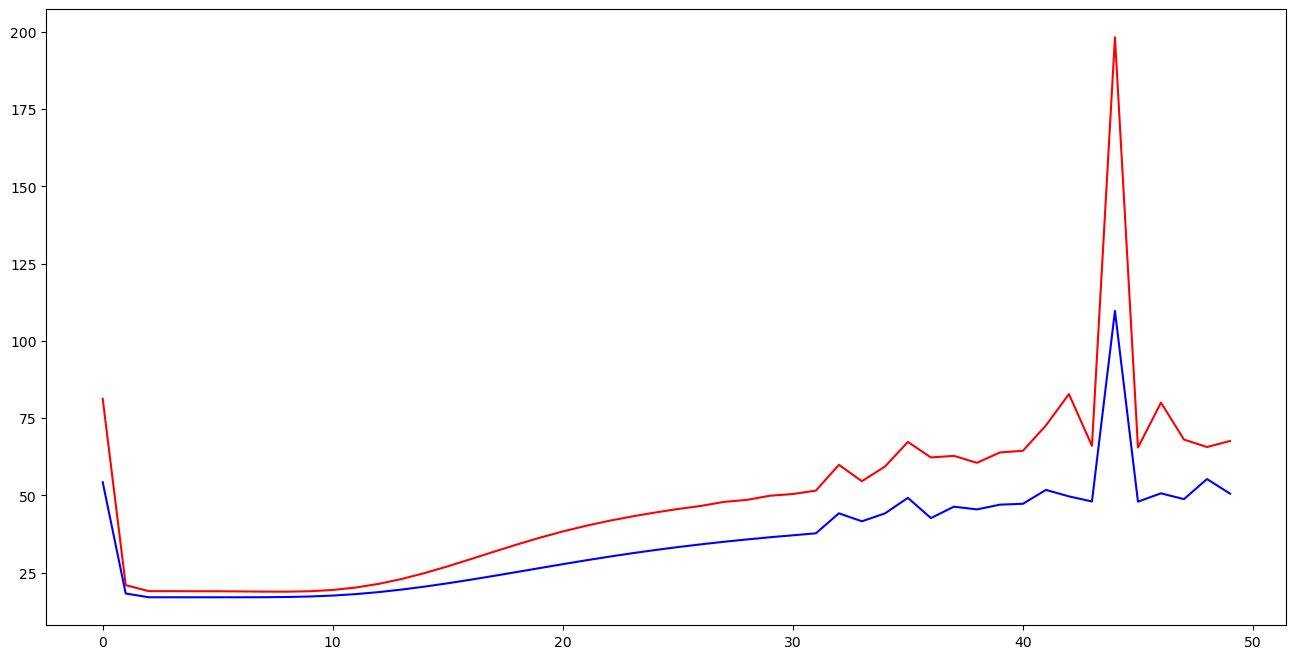

In [75]:
plt.figure(figsize=(16,8))
plt.plot(test_MSE, color="red")
plt.plot(train_MSE, color="blue")

## 3.5 Excercises

##### Question 1: See section 3.3

##### Question 2: See section 3.3

##### Question 3: See section 3.3

##### Question 4: See section 3.3

##### Question 5: See section 3.3

##### Question 6: See section 3.5

##### Question 7: A new car just came on the market with a weight of 2071 pounds. What MPG can we expect of this car?

##### Question 8: Have another look at the heatmap from section 3.3. Can you spot another variable that might bring an improvement to the model? Figure out the best degree and retrain the model with 'weight' and the added variabe. Calculate $R^2$ and the MSE. Did the model improve?

##### Question 9: Figure out which columns give the best result. Retrain your models as many times as needed using different columns. figure out the best degree and calculate $R^2$ and the MSE. What is the best model you can achieve?

In [76]:
polymodel.predict(pol_0.fit_transform([[2071]]))

array([23.82178157])

In [84]:
X = df[["weight", "displacement"]]
y = df["mpg"]

train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.25, random_state=42)

multimodel = LinearRegression()
polyfactor = PolynomialFeatures(degree=2)

multimodel.fit(polyfactor.fit_transform(train_X), train_y)

print("R2", multimodel.score(polyfactor.fit_transform(train_X), train_y))
y_pred = multimodel.predict(polyfactor.fit_transform(test_X))
print("MSE:", mean_squared_error(y_pred, test_y))

R2 0.7151638425794794
MSE: 13.626169469382345


In [101]:
X = df[["weight", "displacement", "cylinders", "horsepower", "origin_1", "origin_2", "origin_3", "model"]]
y = df["mpg"]

train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.25, random_state=42)

multimodel = LinearRegression()
polyfactor = PolynomialFeatures(degree=2)

multimodel.fit(polyfactor.fit_transform(train_X), train_y)

print("R2", multimodel.score(polyfactor.fit_transform(train_X), train_y))
y_pred = multimodel.predict(polyfactor.fit_transform(test_X))
print("MSE:", mean_squared_error(y_pred, test_y))

KeyError: "['model'] not in index"

In [102]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin_1,origin_2,origin_3
0,18.0,8,307.0,130,3504,12.0,70,True,False,False
1,15.0,8,350.0,165,3693,11.5,70,True,False,False
2,18.0,8,318.0,150,3436,11.0,70,True,False,False
3,16.0,8,304.0,150,3433,12.0,70,True,False,False
4,17.0,8,302.0,140,3449,10.5,70,True,False,False
